# Task 3 — Reproducible Survey Pipeline Performance Analysis

**Authors:** Sharipkhan Merey and Olzhabek Marzhan  
**Research context:** Trust of students and patients in AI-generated medical recommendations.

This notebook measures the runtime of an **in-memory survey calculation function**, **not** the accuracy or medical safety of an AI system. The survey sample has 10 **synthetic** rows and cannot support empirical trust hypotheses. The 4 configurations are workload sizes (1, 10, 25, 50 repeated calculations), not a comparison of competing AI models. All measured loads were generated in a single local execution environment.

## 1. Reproducible setup and raw log ingestion

Each JSONL line is one measurement. Ten untimed warm-up invocations were excluded by `collector.py` **before** writing these logs; logs contain evaluation runs only. We additionally reject explicitly marked warm-up records if encountered. File reading and writing are outside timed sections.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
if not (root / 'src' / 'process_data.py').exists():
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from process_data import read_measurements, build_summary, write_summary
from visualize import figures
SEED = 42
np.random.seed(SEED)
configuration = json.loads((root/'configs/task3_analysis.json').read_text())
print('Repository root:', root)
print('Fixed bootstrap random seed:', SEED)
print('Workloads:', configuration['loads'])

Repository root: /mnt/data/task3_work/AI_Medical_Trust_Task3
Fixed bootstrap random seed: 42
Workloads: [1, 10, 25, 50]


In [2]:
raw = []
for load in configuration['loads']:
    measurements = read_measurements(root / f'data/raw/load_{load}.jsonl')
    for record in measurements:
        raw.append({**record, 'load': load})
raw_df = pd.DataFrame(raw)
raw_df['phase'] = raw_df.get('phase', pd.Series('evaluation', index=raw_df.index)).fillna('evaluation')
eval_df = raw_df[(raw_df['phase'] != 'warmup') & (~raw_df.get('warmup', pd.Series(False,index=raw_df.index)).fillna(False))].copy()
print('Raw rows:', len(raw_df), '| evaluation rows:', len(eval_df))
print('Warm-ups were run and discarded by collector before JSONL writing: 10 for each load.')
print(eval_df.groupby('load').agg(measurements=('status','size'), errors=('status',lambda x:(x!='ok').sum())).to_string())

Raw rows: 480 | evaluation rows: 480
Warm-ups were run and discarded by collector before JSONL writing: 10 for each load.
      measurements  errors
load                      
1              120       0
10             120       0
25             120       0
50             120       0


## 2. Statistical aggregation and guardrails

We calculate latency mean, median, p25/p75, p95 and p99 for successful runs, with failures included in the error-rate denominator. The **95% bootstrap percentile confidence interval** uses 2,000 resamples and seed 42. The interval covers the median latency **per calculation** in each fixed workload; it is not a clinical confidence interval and does not account for all machine-to-machine variability.

In [3]:
summary = build_summary(root, seed=SEED, replicates=configuration['bootstrap_replicates'])
write_summary(summary, root/'data/processed/metrics_summary.csv')
summary_df = pd.DataFrame(summary)
cols=['load','measurements','errors','error_rate','median_latency_us','p95_latency_us','p99_latency_us','median_us_per_calculation','ci95_low_us_per_calculation','ci95_high_us_per_calculation']
print(summary_df[cols].round(3).to_string(index=False))
assert len(eval_df)==480 and (summary_df['measurements']==120).all()
assert all(0 <= v <= 1 for v in summary_df['error_rate'])

 load  measurements  errors  error_rate  median_latency_us  p95_latency_us  p99_latency_us  median_us_per_calculation  ci95_low_us_per_calculation  ci95_high_us_per_calculation
    1           120       0         0.0             13.796          16.839          42.064                     13.796                       13.715                        13.901
   10           120       0         0.0            131.662         279.380         690.183                     13.166                       13.121                        13.284
   25           120       0         0.0            343.691         461.890         610.559                     13.748                       13.394                        13.907
   50           120       0         0.0            700.431         987.109        1153.432                     14.009                       13.641                        14.627


## 3. Scientific visualizations

Figure 1 compares **latency per calculation** against batch size with bootstrapped 95% confidence bars. Figure 2 uses boxplots for the baseline (single calculation) and the batch-50 configuration, alongside median confidence intervals. Units are microseconds; accessible colors and markers supplement color encoding. Both plots are exported as PDF and PNG (320 dpi).

fig1_latency_vs_load => True True
fig2_distribution_boxplot => True True


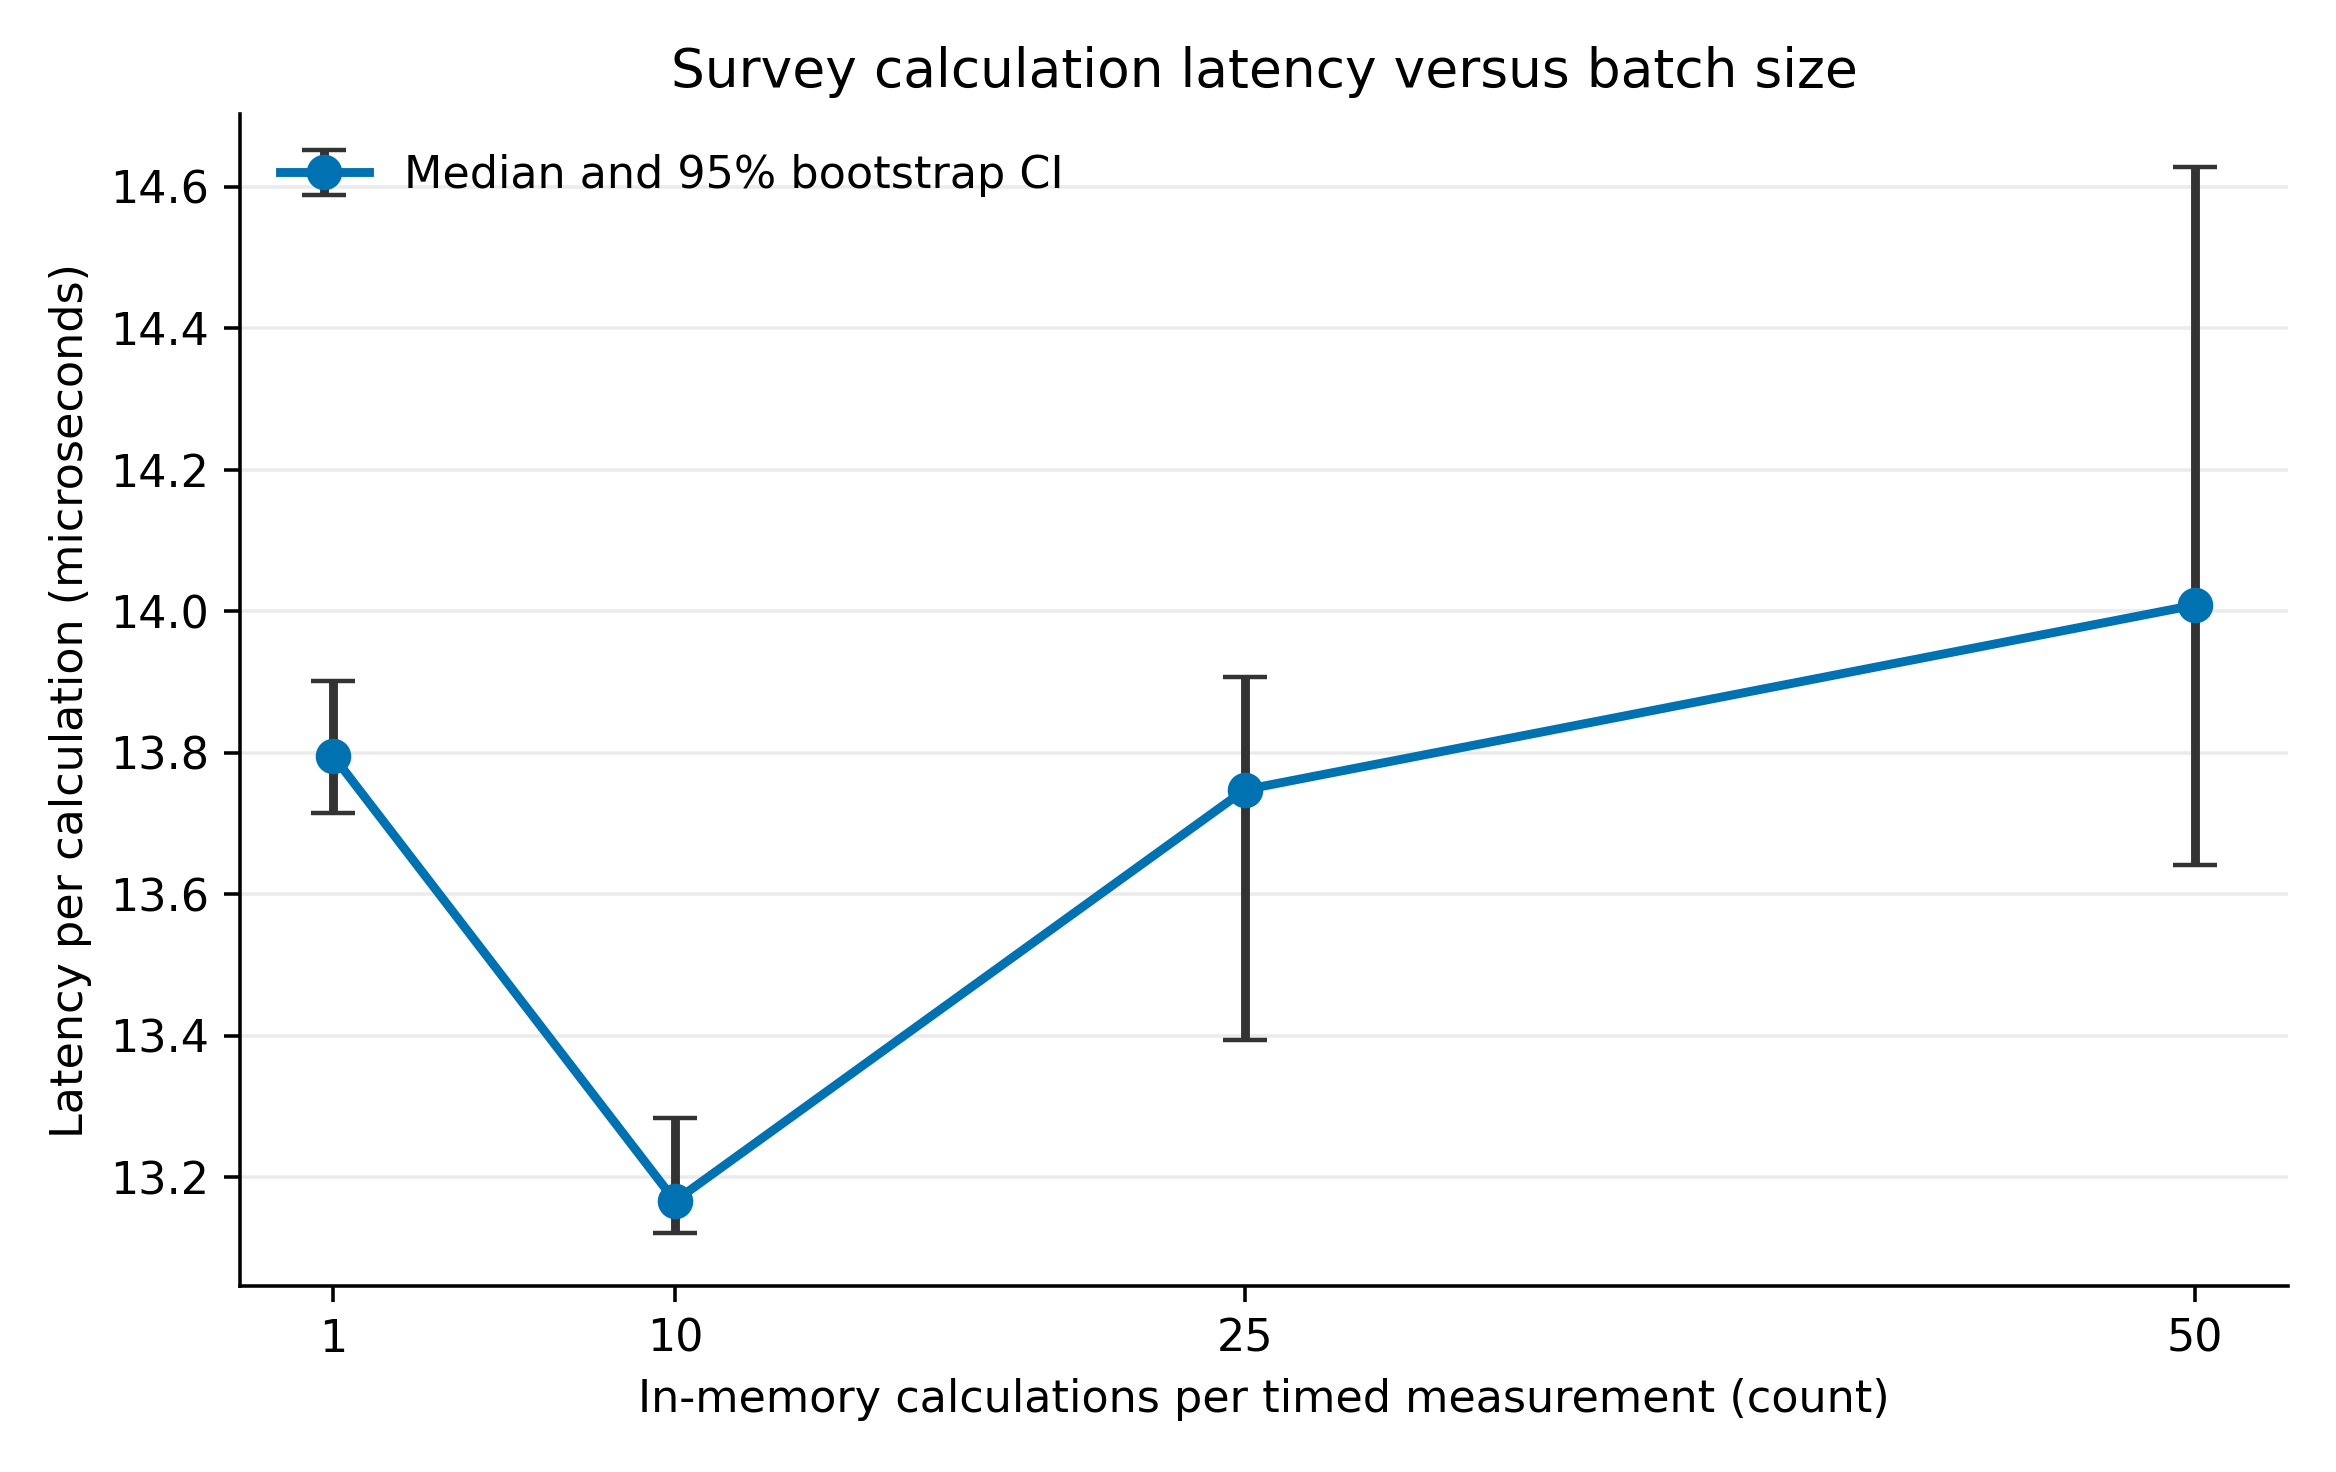

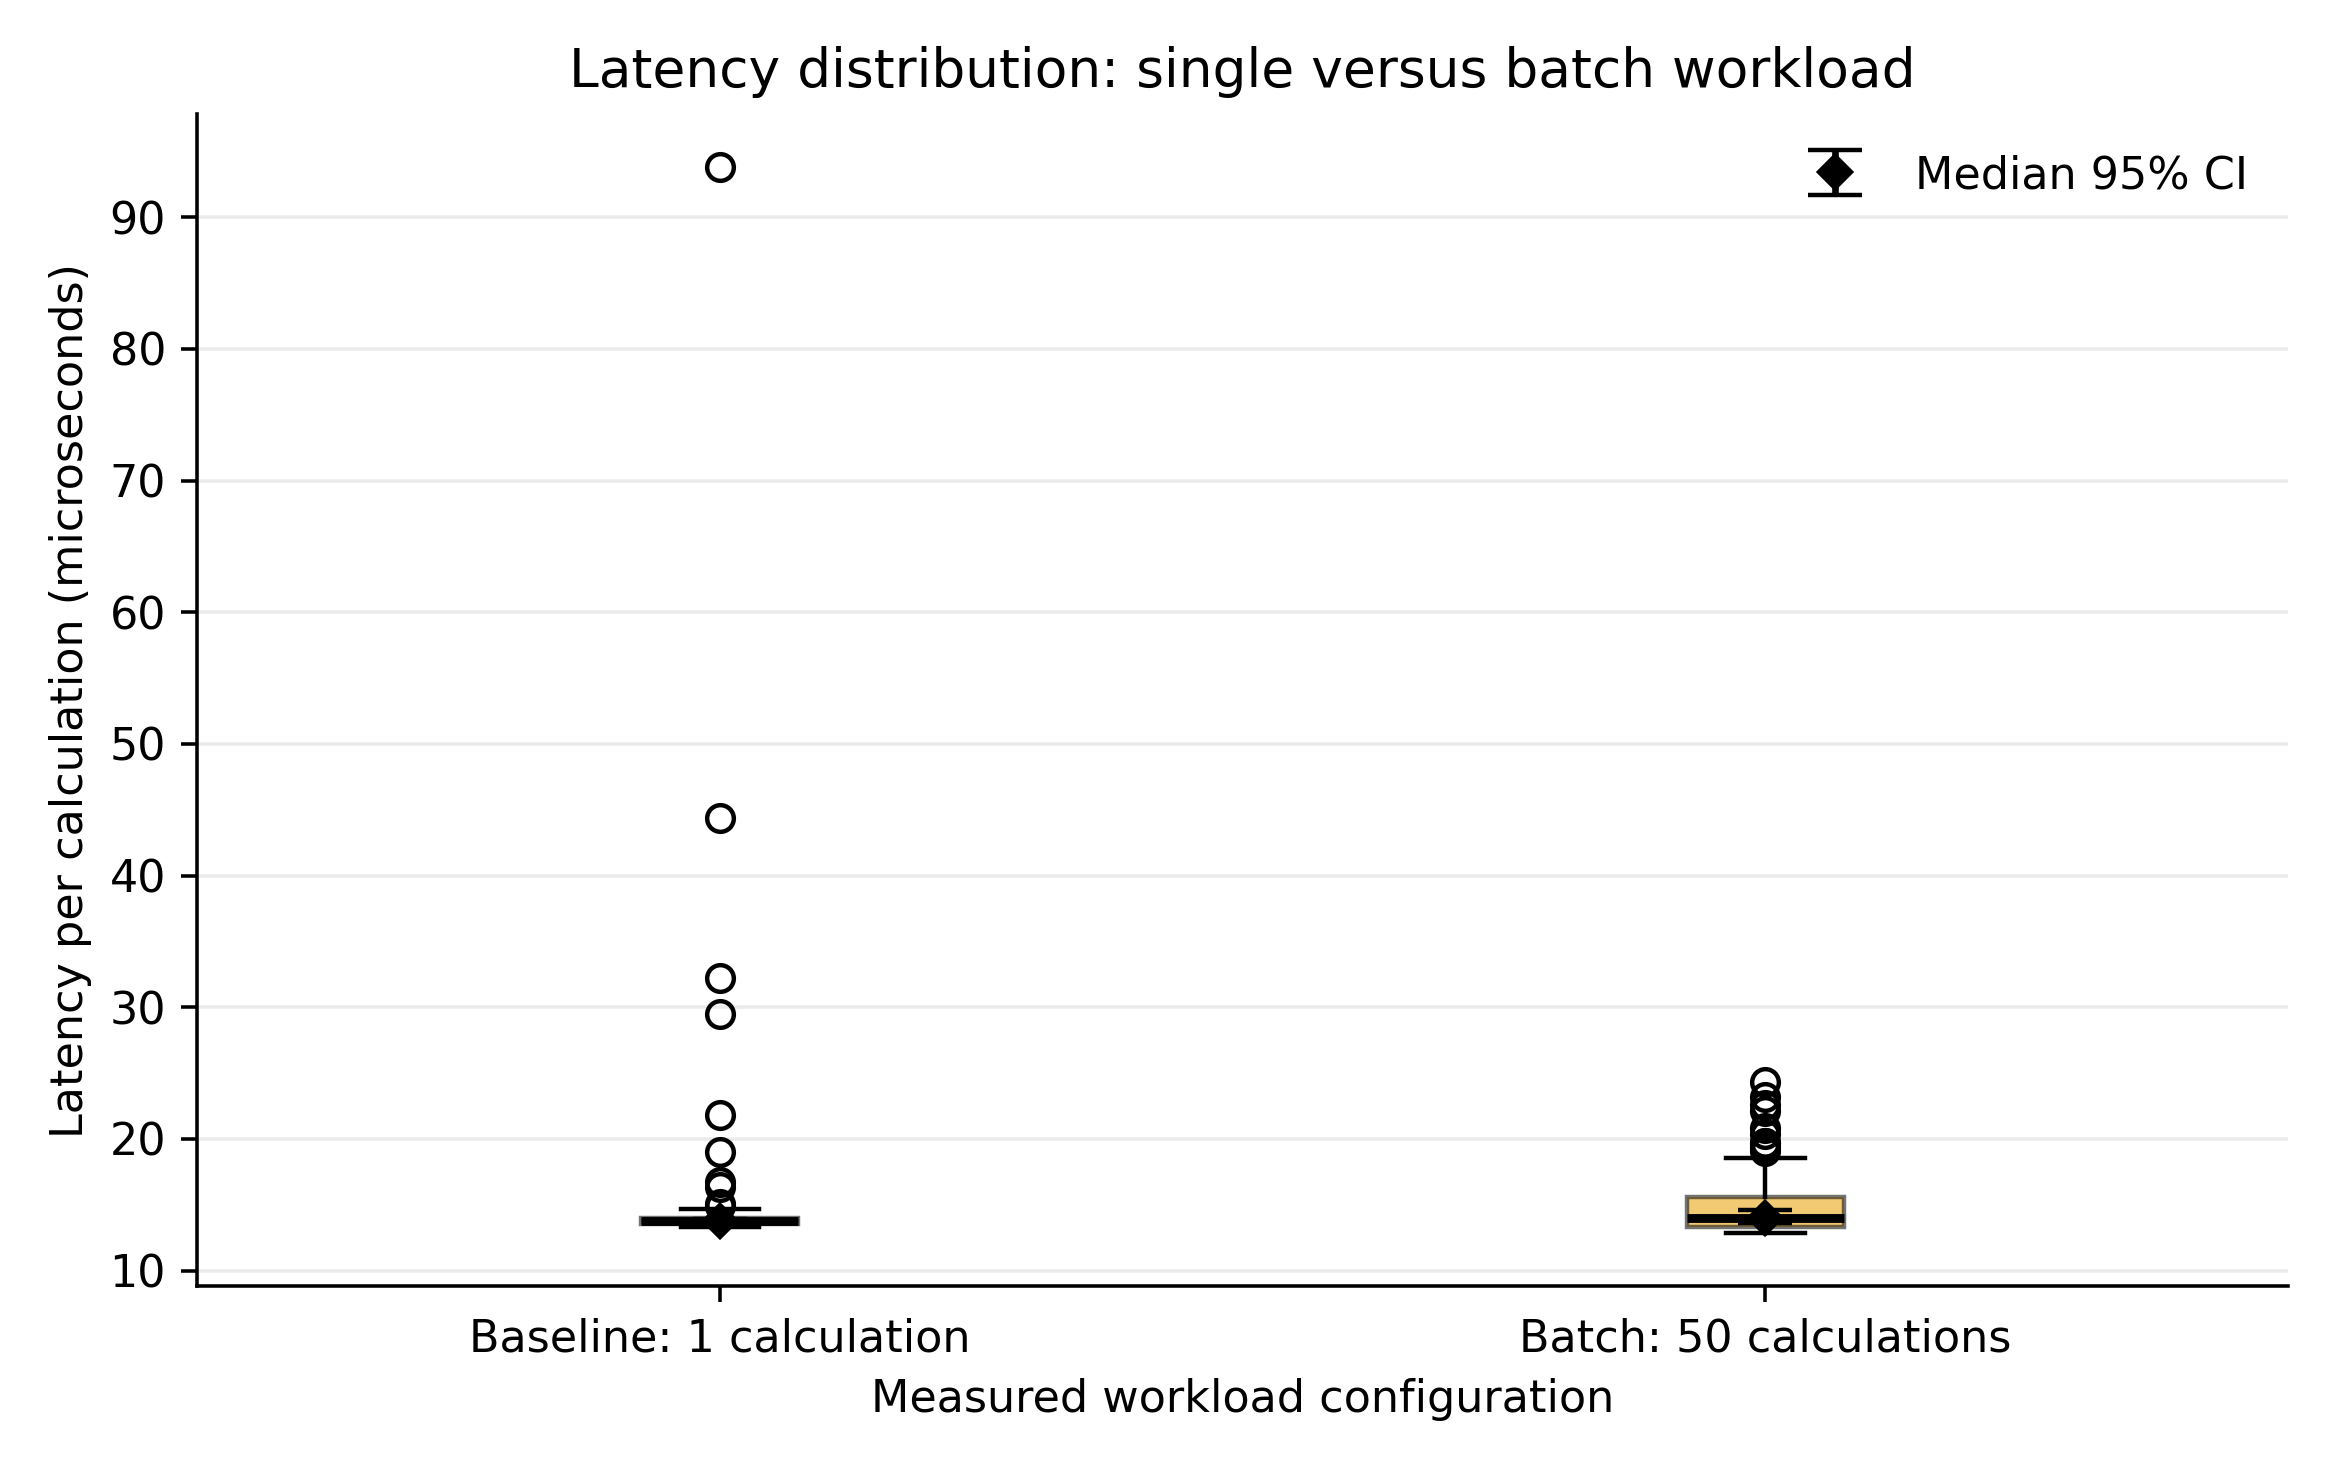

In [4]:
figures(root)
for name in ['fig1_latency_vs_load','fig2_distribution_boxplot']:
    print(name, '=>', (root/f'reports/figures/{name}.png').exists(), (root/f'reports/figures/{name}.pdf').exists())
from IPython.display import display, Image
display(Image(filename=str(root/'reports/figures/fig1_latency_vs_load.png'),width=650))
display(Image(filename=str(root/'reports/figures/fig2_distribution_boxplot.png'),width=650))

## 4. Interpretation and limitations

The **baseline** is one calculation per timed measurement; the **proposed batch configuration** repeats a fixed in-memory calculation 50 times per timed measurement. Both use identical synthetic data and the same computational function. This is a controlled **workload comparison**, not evidence that an improved medical algorithm exists. Per-calculation latency is derived by dividing the batch duration by the number of calculations.

There are no real patient or student observations. These logs measure execution of the data-processing pipeline only. Ten warm-up calls per configuration were not timed or logged. Measurements may be correlated and environment-specific; a bootstrap CI is a conditional uncertainty summary, not a performance guarantee. Collect anonymized real surveys and perform inferential testing in a later stage.